In [ ]:
from google.colab import drive, userdata
import os
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
import datetime as dt
from scipy.stats import chi2_contingency, shapiro, mannwhitneyu, pointbiserialr, pearsonr, spearmanr

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import geopandas as gpd
#!pip install cartopy --quiet
import cartopy.io.shapereader as shpreader
#!pip install dython --quiet
from dython.nominal import associations

# NLP
#!pip install vaderSentiment --quiet
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
#!pip install anthropic --quiet
import anthropic
import json
import time

# CatBoost Modeling
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
!pip install catboost --quiet
from catboost import CatBoostClassifier, Pool

In [ ]:
drive.mount('/content/drive')
df_raw = pd.read_csv('/content/drive/MyDrive/Laboratorio II/retail_lab_2.csv')
df = df_raw.copy()

# **EDA and Wrangling**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8047 entries, 0 to 8046
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Order ID          8047 non-null   object
 1   Order Date        8047 non-null   object
 2   Country           8047 non-null   object
 3   Category          8047 non-null   object
 4   Sub-Category      8047 non-null   object
 5   Segment           8047 non-null   object
 6   Ship Mode         8047 non-null   object
 7   Discount, Profit  8047 non-null   object
 8   FeedbackText      8047 non-null   object
 9   RepeatPurchase    8047 non-null   int64 
dtypes: int64(1), object(9)
memory usage: 628.8+ KB


In [ ]:
# Duplicate check
df.duplicated().sum()

np.int64(0)

**Target Variable: RepeatPurchase**

In [ ]:
# Checking class balance of the target variable
round(df['RepeatPurchase'].value_counts(normalize=True), 2)

,proportion
RepeatPurchase,
1,0.56
0,0.44


**Order ID**

We don't know what the Order ID prefix means (it could be the warehouse, the region, the vendor, a product line), but it's possible that if we isolate it as a categorical variable, it has an association with RepeatPurchase.

In [ ]:
# Extracting the prefix and obtaining the contingency table with RepeatPurchase
order_prefix = df['Order ID'].str.split('-').str[0]

# Absolute values
counts = pd.crosstab(
    index=order_prefix,
    columns=df['RepeatPurchase']
)

# Percentages
percentages = pd.crosstab(
    index=order_prefix,
    columns=df['RepeatPurchase'],
    normalize='index'
).round(2)

result = pd.concat(
    {
        'Count': counts,
        'Percentage': percentages
    },
    axis=1
)

result

Count       Percentage      
RepeatPurchase     0     1          0     1
Order ID                                   
AZ              2314  3906       0.37  0.63
BN              1241   586       0.68  0.32

In [ ]:
# Incorporating into the dataframe
df['Order Prefix'] = order_prefix

In [ ]:
# Contingency table (counts, not proportions)
ct = pd.crosstab(df['Order Prefix'], df['RepeatPurchase'])

# Chi-square test of independence
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Phi coefficient (2x2 case of Cramér's V)
phi = np.sqrt(chi2 / n)

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"phi coefficient: {phi:.4f}")


estadístico chi2: 539.2733
p-value: 0.000000
n: 8047
coeficiente phi: 0.2589


Upon performing a chi-squared test, with a p-value of 0.000000 and a phi coefficient of 0.2589, the Order Prefix variable shows a weak-to-moderate association with RepeatPurchase, which makes it a good candidate for our model.

In [ ]:
df = df.drop(columns='Order ID')

**Order Date**

We can assume that the month, the half-month, or the day of the week may be associated with RepeatPurchase. Therefore, we are going to create features from Order Date.

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Extraemos el mes
df['Month'] = df['Order Date'].dt.month_name()  # Usar .dt.month para obtener el número (1-12)

# Creamos la columna de quincena
df['Half-month'] = df['Order Date'].dt.day.apply(lambda d: '1st Half' if d <= 15 else '2nd Half')

# Extraemos el día de la semana
df['Weekday'] = df['Order Date'].dt.day_name()  # Usar .dt.weekday para obtener el número (0=Mon, 6=Sun)

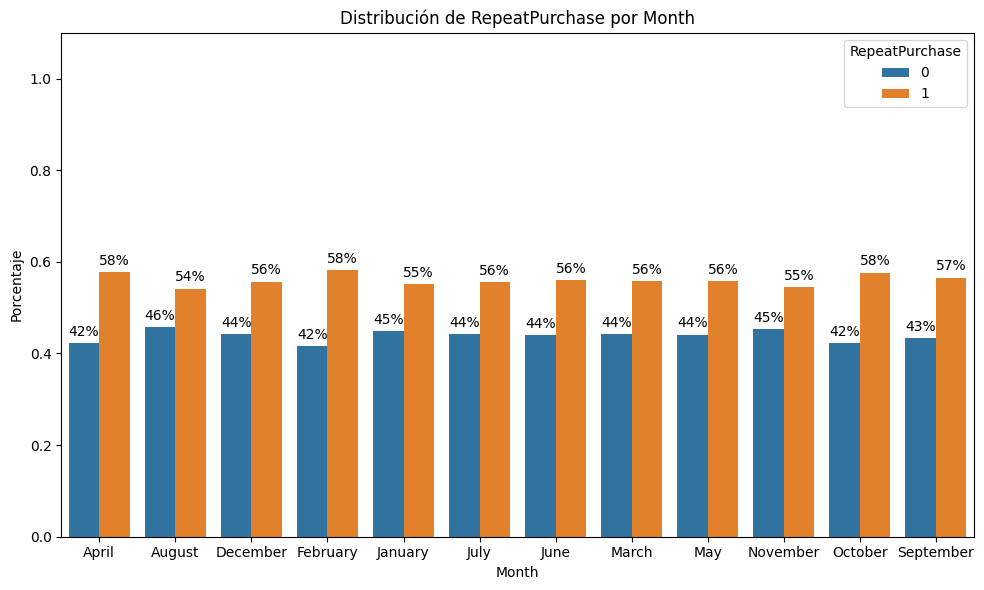

In [ ]:
# Calculating percentages
month_purchase = pd.crosstab(
    index=df['Month'],
    columns=df['RepeatPurchase'],
    normalize='index'
).reset_index()

# Converting to long format
plot_df = month_purchase.melt(
    id_vars='Month',
    var_name='RepeatPurchase',
    value_name='Percentage'
)

# Plotting
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_df,
    x='Month',
    y='Percentage',
    hue='RepeatPurchase'
)

# Adding percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{bar.get_height():.0%}' for bar in container],
        padding=3
    )

plt.title('RepeatPurchase Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Percentage')
plt.ylim(0, 1.1)
plt.legend(title='RepeatPurchase')

plt.tight_layout()
plt.show()

In [ ]:
# Absolute values
counts = pd.crosstab(
    index=df['Half-month'],
    columns=df['RepeatPurchase']
)

# Percentages
percentages = pd.crosstab(
    index=df['Half-month'],
    columns=df['RepeatPurchase'],
    normalize='index'
).round(2)

result = pd.concat(
    {
        'Count': counts,
        'Percentage': percentages
    },
    axis=1
)

result

Count       Percentage      
RepeatPurchase     0     1          0     1
Half-month                                 
1st Half        1752  2210       0.44  0.56
2nd Half        1803  2282       0.44  0.56

In [ ]:
# Absolute values
counts = pd.crosstab(
    index=df['Weekday'],
    columns=df['RepeatPurchase']
)

# Percentages
percentages = pd.crosstab(
    index=df['Weekday'],
    columns=df['RepeatPurchase'],
    normalize='index'
).round(2)

result = pd.concat(
    {
        'Count': counts,
        'Percentage': percentages
    },
    axis=1
)

result

Count      Percentage      
RepeatPurchase     0    1          0     1
Weekday                                   
Friday           618  816       0.43  0.57
Monday           675  803       0.46  0.54
Saturday         355  410       0.46  0.54
Sunday            58  117       0.33  0.67
Thursday         595  750       0.44  0.56
Tuesday          657  806       0.45  0.55
Wednesday        597  790       0.43  0.57

As shown by the contingency tables and the bar chart, the distribution of RepeatPurchase remains similar across the categories of the features created from Order Date. Sundays in Weekday is the only category that shows a different distribution, but given the low absolute values (175 observations in total), we decided not to continue exploring these variables since they do not promise predictive value. After analyzing the interaction between variables, we will decide whether to drop these variables.

In [ ]:
# Eliminating Order Date
df = df.drop(columns='Order Date')

**Country**

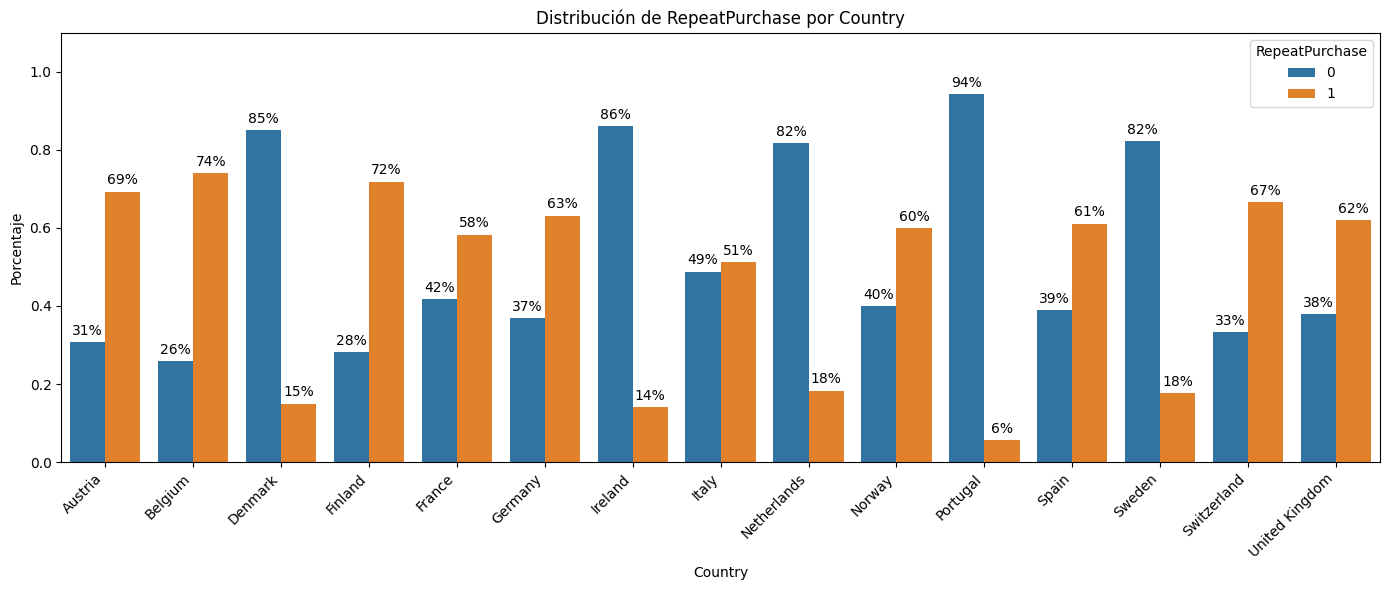

In [ ]:
# Barplot between Country and RepeatPurchase (percentages)

# Calculating percentages
country_purchase = pd.crosstab(
    index=df['Country'],
    columns=df['RepeatPurchase'],
    normalize='index'
).reset_index()

# Converting to long format
plot_df = country_purchase.melt(
    id_vars='Country',
    var_name='RepeatPurchase',
    value_name='Percentage'
)

# Plotting
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=plot_df,
    x='Country',
    y='Percentage',
    hue='RepeatPurchase'
)

# Adding percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{bar.get_height():.0%}' for bar in container],
        padding=3
    )

plt.title('RepeatPurchase Distribution by Country')
plt.xlabel('Country')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Percentage')
plt.ylim(0, 1.1)
plt.legend(title='RepeatPurchase')

plt.tight_layout()
plt.show()

In [ ]:
# Contingency Table
ct = pd.crosstab(df['Country'], df['RepeatPurchase'])

# Chi-square Independence Test
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Cramér's V (more than 2 categories in at least one variable)
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")


estadístico chi2: 653.2678
p-value: 0.000000
n: 8047
grados de libertad: 14
Cramér's V: 0.2849


Upon performing a chi-squared test, with a p-value of 0.000000 and a phi coefficient of 0.2849, the Country variable shows a weak-to-moderate association with RepeatPurchase, which makes it a good candidate for our model.

From the EDA, it emerged that Order Prefix appears to show an association with Country. We will analyze this association in greater detail.

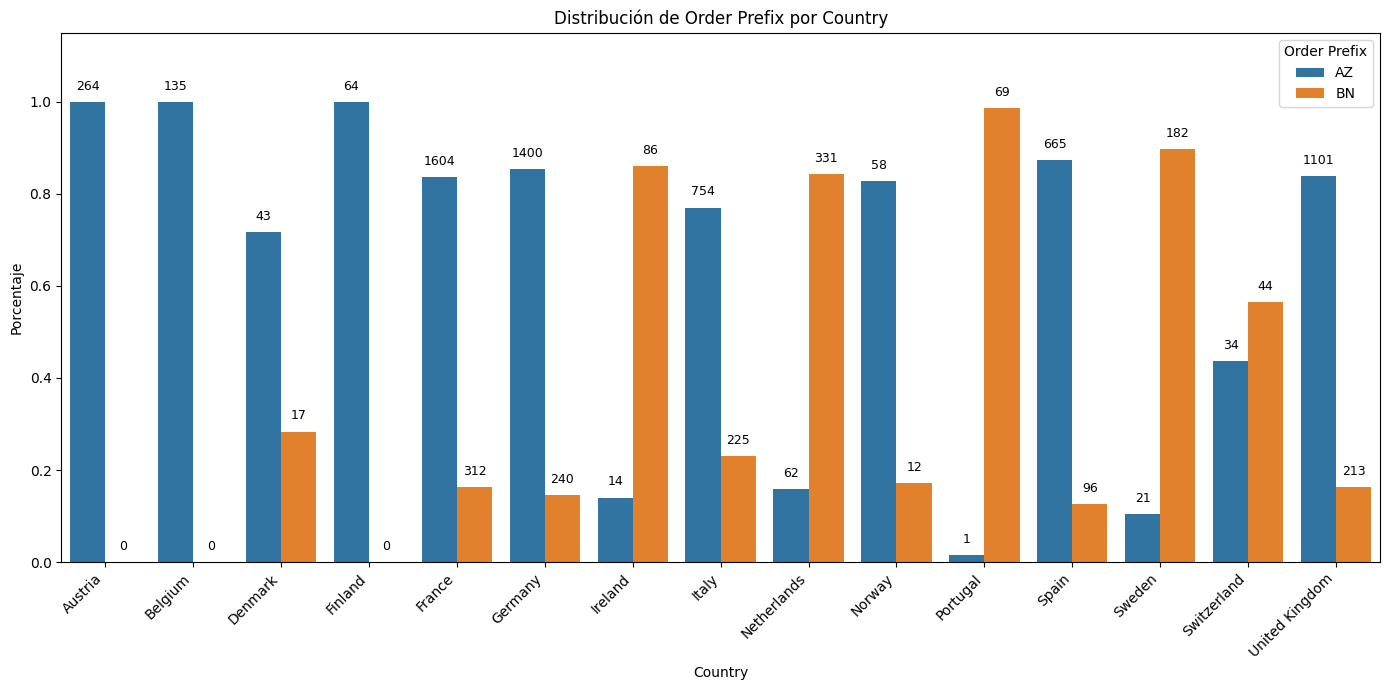

In [ ]:
#  Percentages
pct = pd.crosstab(
    index=df['Country'],
    columns=df['Order Prefix'],
    normalize='index'
)

# Absolute values
counts = pd.crosstab(
    index=df['Country'],
    columns=df['Order Prefix']
)

# Converting to long format
plot_df = pct.reset_index().melt(
    id_vars='Country',
    var_name='Order Prefix',
    value_name='Percentage'
)

# Adding absolute values
count_df = counts.reset_index().melt(
    id_vars='Country',
    var_name='Order Prefix',
    value_name='Count'
)

plot_df['Count'] = count_df['Count']

# Plotting
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=plot_df,
    x='Country',
    y='Percentage',
    hue='Order Prefix'
)

# Adding percentage labels + absolute value labels
for container, prefix in zip(ax.containers, ['AZ', 'BN']):
    for bar, (_, row) in zip(container, plot_df[plot_df['Order Prefix'] == prefix].iterrows()):
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f'{row["Count"]}',
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.title('Order Prefix Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Percentage')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.15)
plt.legend(title='Order Prefix')
plt.tight_layout()

plt.show()

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/tmp/ipykernel_737/1864336818.py:48: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  (europe.geometry.centroid.y > 72)


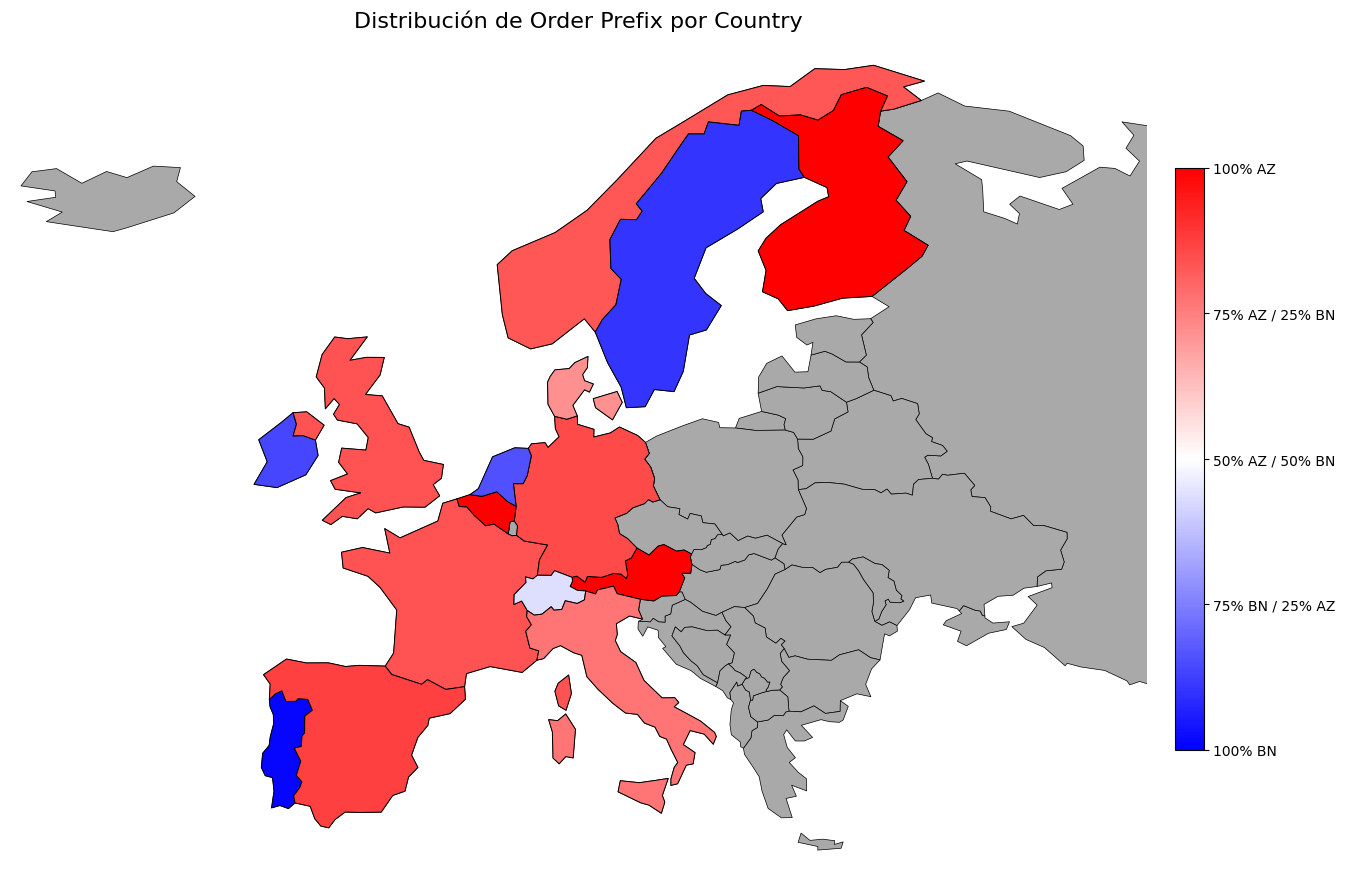

In [ ]:
# Visualizing predominantly AZ and BN countries by color
# ---------------------------------------------------------
# 1. Calculating the proportion of AZ for each country
# ---------------------------------------------------------

country_pct = (
    pd.crosstab(
        index=df['Country'],
        columns=df['Order Prefix'],
        normalize='index'
    )['AZ']
    .rename('AZ_pct')
    .reset_index()
)

# ---------------------------------------------------------
# 2. Loading country boundaries from Natural Earth
# ---------------------------------------------------------

shp = shpreader.natural_earth(
    resolution='110m',
    category='cultural',
    name='admin_0_countries'
)

world = gpd.read_file(shp)

# ---------------------------------------------------------
# 3. Conserving European countries
# ---------------------------------------------------------

europe = world[world['CONTINENT'] == 'Europe'].copy()

# ---------------------------------------------------------
# 4. Eliminating Svalbard
#    and other regions outside Europe
# ---------------------------------------------------------

# Restricting the map approximately to European mainland.
# Eliminating French Guiana.
europe = europe.cx[-25:45, 34:72]

# Eliminating Svalbard explicitly.
# Svalbard is part of Norway in the Natural Earth dataset.
europe = europe[
    ~(
        (europe['ADMIN'] == 'Norway') &
        (europe.geometry.centroid.y > 72)
    )
]

# ---------------------------------------------------------
# 5. Mapping country names between df and Natural Earth
# ---------------------------------------------------------

country_mapping = {
    'Austria': 'Austria',
    'Belgium': 'Belgium',
    'Denmark': 'Denmark',
    'Finland': 'Finland',
    'France': 'France',
    'Germany': 'Germany',
    'Ireland': 'Ireland',
    'Italy': 'Italy',
    'Netherlands': 'Netherlands',
    'Norway': 'Norway',
    'Portugal': 'Portugal',
    'Spain': 'Spain',
    'Sweden': 'Sweden',
    'Switzerland': 'Switzerland',
    'United Kingdom': 'United Kingdom'
}

# Merging the percentages with the geographical data
europe = europe.merge(
    country_pct,
    left_on='ADMIN',
    right_on='Country',
    how='left'
)

# ---------------------------------------------------------
# 6. Creating red → blue scale
#    1.0 AZ = red
#    0.0 AZ / 1.0 BN = blue
# ---------------------------------------------------------

cmap = mcolors.LinearSegmentedColormap.from_list(
    'AZ_to_BN',
    ['blue', 'white', 'red']
)

norm = mcolors.Normalize(vmin=0, vmax=1)

# ---------------------------------------------------------
# 7. Plotting
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 10))

# Countries without data
europe.plot(
    ax=ax,
    color='darkgray',
    edgecolor='black',
    linewidth=0.5
)

# Countries with data
europe[europe['AZ_pct'].notna()].plot(
    ax=ax,
    column='AZ_pct',
    cmap=cmap,
    norm=norm,
    edgecolor='black',
    linewidth=0.7
)

# ---------------------------------------------------------
# 8. Colorbar
# ---------------------------------------------------------

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.6,
    pad=0.02
)

cbar.set_ticks([0, 0.25, 0.50, 0.75, 1.0])
cbar.set_ticklabels([
    '100% BN',
    '75% BN / 25% AZ',
    '50% AZ / 50% BN',
    '75% AZ / 25% BN',
    '100% AZ'
])

# ---------------------------------------------------------
# 9. Formatting
# ---------------------------------------------------------

ax.set_title(
    'Order Prefix Distribution by Country',
    fontsize=16,
    pad=15
)

ax.set_xlim(-25, 45)
ax.set_ylim(34, 72)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
# Contingency Table
ct = pd.crosstab(df['Country'], df['Order Prefix'])

# Chi-square test of independence
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Cramér's V
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")


estadístico chi2: 2194.3527
p-value: 0.000000
n: 8047
grados de libertad: 14
Cramér's V: 0.5222


Although the map shows that Order Prefix does not divide the dataset into geographically contiguous regions, the chi-squared test and Cramér's V demonstrate that there is a moderate-to-strong association between these two variables. A tree-based model can handle this association well, but it is good to be aware of it.

**Category, Sub-Category and Segment**

We will check whether columns Category, Sub-Category and Segment are redundant.

In [ ]:
pd.crosstab(
    index=df['Category'],
    columns=df['Sub-Category']
)

Sub-Category,Accessories,Appliances,Art,Binders,Bookcases,Chairs,Copiers,Envelopes,Fasteners,Furnishings,Labels,Machines,Paper,Phones,Storage,Supplies,Tables
Category,,,,,,,,,,,,,,,,,
Furniture,0,0,0,0,391,383,0,0,0,389,0,0,0,0,0,0,75
Office Supplies,0,235,1152,1059,0,0,0,346,350,0,372,0,374,0,1051,347,0
Technology,368,0,0,0,0,0,367,0,0,0,0,335,0,453,0,0,0


In [ ]:
# Obtaining the smallest class size in Sub-Category to evaluate the suitability of the Chi2 test
df['Sub-Category'].value_counts().min()

75

In [ ]:
# Getting association statistics for Category and Sub-Category
for col in ['Category', 'Sub-Category']:
    ct = pd.crosstab(df[col], df['RepeatPurchase'])
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()
    r, k = ct.shape
    v = np.sqrt((chi2/n) / (min(r-1, k-1)))
    print(f"{col}: chi2={chi2:.2f}, p={p:.6f}, Cramér's V={v:.4f}")

Category: chi2=133.12, p=0.000000, Cramér's V=0.1286
Sub-Category: chi2=272.95, p=0.000000, Cramér's V=0.1842


It is reasonable to drop Category in favor of Sub-Category, since it has a greater association with RepeatPurchase (0.1842).

In [ ]:
df = df.drop(columns='Category')

Checking association between Segment and Sub-Category.

In [ ]:
# Contingency Table
ct = pd.crosstab(df['Sub-Category'], df['Segment'])
print(ct)

# Chi-square test of independence
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Cramér's V
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")

Segment       Consumer  Corporate  Home Office
Sub-Category                                  
Accessories        179        132           57
Appliances         117         80           38
Art                627        324          201
Binders            545        343          171
Bookcases          212        114           65
Chairs             203        117           63
Copiers            186        113           68
Envelopes          178        120           48
Fasteners          182        106           62
Furnishings        195        134           60
Labels             198        113           61
Machines           180        105           50
Paper              188        108           78
Phones             246        149           58
Storage            543        309          199
Supplies           157        121           69
Tables              38         26           11

estadístico chi2: 39.4444
p-value: 0.171365
n: 8047
grados de libertad: 32
Cramér's V: 0.0495


Segment seems to be independent from Sub-Category, therefore we will assess it against RepeatPurchase.

In [ ]:
# Contingency Table
ct = pd.crosstab(df['Segment'], df['RepeatPurchase'])
print(ct)

# Chi-square test of independence
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Cramér's V
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")

RepeatPurchase     0     1
Segment                   
Consumer        1832  2342
Corporate       1097  1417
Home Office      626   733

estadístico chi2: 2.3982
p-value: 0.301467
n: 8047
grados de libertad: 2
Cramér's V: 0.0173


Segment shows no direct association with RepeatPurchase, neither in terms of statistical significance nor in terms of effect size.

**Ship Mode**

In [ ]:
# Contingency Table
ct = pd.crosstab(df['Ship Mode'], df['RepeatPurchase'])
print(ct)

# Chi-square test of independence
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.sum().sum()

# Cramér's V
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"\nchi2 statistic: {chi2:.4f}")
print(f"p-value: {p:.6f}")
print(f"n: {n}")
print(f"degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")

RepeatPurchase     0     1
Ship Mode                 
Economy         2154  2708
Economy Plus     719   871
Immediate        173   253
Priority         509   660

estadístico chi2: 3.1217
p-value: 0.373246
n: 8047
grados de libertad: 3
Cramér's V: 0.0197


Ship Mode shows no direct association with RepeatPurchase, neither in terms of statistical significance nor in terms of effect size.

**Discount, Profit**

In [ ]:
# Getting separate columns 'Discount' and 'Profit' from 'Discount, Profit'
df[['Discount', 'Profit']] = (
    df['Discount, Profit']
    .str.extract(r'Discount:\s*([-+]?\d*\.?\d+),\s*Profit:\s*([-+]?\d*\.?\d+)')
    .astype(float)
)
df = df.drop(columns='Discount, Profit')
df.columns

Index(['Country', 'Sub-Category', 'Segment', 'Ship Mode', 'FeedbackText',
       'RepeatPurchase', 'Order Prefix', 'Month', 'Half-month', 'Weekday',
       'Discount', 'Profit'],
      dtype='object')

In [ ]:
# Checking if the distribution of Discount and Profit is normal
for col in ['Discount', 'Profit']:
    stat, p = shapiro(df[col].sample(min(5000, len(df)), random_state=42))  # Shapiro has a sample size limit
    print(f"{col}: Shapiro-Wilk p-value = {p:.6f}")

Discount: Shapiro-Wilk p-value = 0.000000
Profit: Shapiro-Wilk p-value = 0.000000


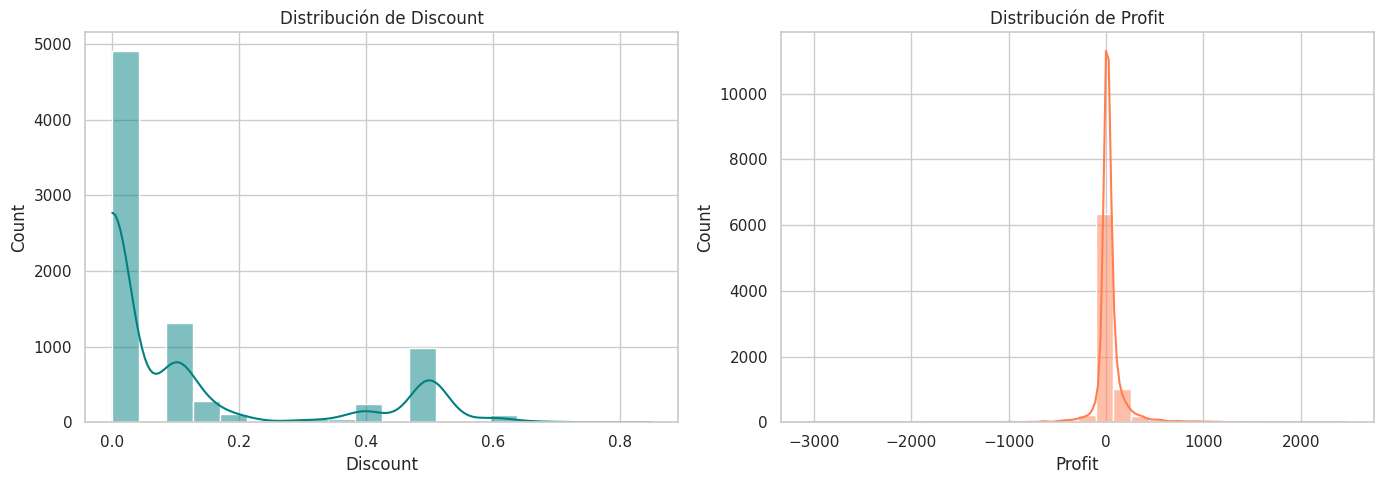

In [ ]:
# Configuring the style
sns.set_theme(style="whitegrid")

# Creating a figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Discount Distribution
sns.histplot(df['Discount'], kde=True, ax=axes[0], color='teal', bins=20)
axes[0].set_title('Discount Distribution', fontsize=12)
axes[0].set_xlabel('Discount')
axes[0].set_ylabel('Count')

# Plot 2: Profit Distribution
sns.histplot(df['Profit'], kde=True, ax=axes[1], color='coral', bins=30)
axes[1].set_title('Profit Distribution', fontsize=12)
axes[1].set_xlabel('Profit')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

The Shapiro-Wilk test suggests that these variables are not normally distributed. Given that they are non-normal, we will use the Mann-Whitney U test to check whether these variables, when segmented by RepeatPurchase, have significantly different values.

In [ ]:
# Mann-Whitney U Test
for col in ['Discount', 'Profit']:
    group0 = df[df['RepeatPurchase'] == 0][col]
    group1 = df[df['RepeatPurchase'] == 1][col]
    stat, p = mannwhitneyu(group0, group1)
    print(f"{col}: Mann-Whitney U p-value = {p:.6f}")

Discount: Mann-Whitney U p-value = 0.000000
Profit: Mann-Whitney U p-value = 0.000000


In [ ]:
# Checking the point-biserial correlation of Discount and Profit with RepeatPurchase
for col in ['Discount', 'Profit']:
    corr, p = pointbiserialr(df['RepeatPurchase'], df[col])
    print(f"{col}: point-biserial r = {corr:.4f}, p-value = {p:.6f}")

Discount: point-biserial r = -0.3727, p-value = 0.000000
Profit: point-biserial r = 0.3180, p-value = 0.000000


Both variables have a moderate correlation with RepeatPurchase. We will check whether Discount and Profit are correlated with each other.

In [ ]:
corr, p = pearsonr(df['Discount'], df['Profit'])
print(f"Discount vs Profit: r = {corr:.4f}, p = {p:.6f}")

Discount vs Profit: r = -0.3513, p = 0.000000


There is a moderate negative correlation between these variables. This should be kept in mind prior to modeling.

**FeedbackText**

In [ ]:
# We can run this cell multiple times to see examples of text and RepeatPurchase
df[['RepeatPurchase', 'FeedbackText']].sample(1)

,RepeatPurchase,FeedbackText
5040,0,Disappointed with the delayed binders delivery despite selecting priority shipping and expecting timely corporate orders from Holland.


We will perform sentiment analysis with VADER as a baseline.

In [ ]:
# Performing sentiment analysis with VADER
analyzer = SentimentIntensityAnalyzer()

scores = df['FeedbackText'].apply(analyzer.polarity_scores)
df['sentiment_compound'] = scores.apply(lambda x: x['compound'])
df['sentiment_neg'] = scores.apply(lambda x: x['neg'])
df['sentiment_pos'] = scores.apply(lambda x: x['pos'])

In [ ]:
# We can run this cell multiple times to see examples of text and sentiment_compound
df_samples = pd.concat([
    df[df['sentiment_compound'] < -0.05][['sentiment_compound', 'FeedbackText']].sample(1),
    df[(df['sentiment_compound'] >= -0.05) & (df['sentiment_compound'] <= 0.05)][['sentiment_compound', 'FeedbackText']].sample(1),
    df[df['sentiment_compound'] > 0.05][['sentiment_compound', 'FeedbackText']].sample(1)
], ignore_index=True)

df_samples

,sentiment_compound,FeedbackText
0,-0.4710,I couldn't be happier with our order of copiers!
1,0.0000,I purchased 7 chairs for my office in Paris via the economy shipping option from an overseas supplier.
2,0.8655,Economically priced and perfectly sturdy tabletops for the office – exactly what we needed to boost our corporate setting's efficiency!


From the previous check, it turns out that there is text in French (and perhaps in other languages) and spelling errors that VADER cannot handle. We are going to try with Claude.

In [ ]:
df = df.drop(columns=['sentiment_compound', 'sentiment_neg', 'sentiment_pos'])
df.columns

Index(['Country', 'Sub-Category', 'Segment', 'Ship Mode', 'FeedbackText',
       'RepeatPurchase', 'Order Prefix', 'Month', 'Half-month', 'Weekday',
       'Discount', 'Profit'],
      dtype='object')

In [ ]:
SYSTEM_PROMPT = """You are analyzing customer product reviews. For each review,
determine sentiment: a score from -1.0 (very negative) to 1.0 (very positive).

Reviews may be in English, Swedish, French, Italian, German, Spanish, Dutch, Danish,
Norwegian, Portuguese, or Finnish and may contain typos. Interpret meaning,
not exact wording.

Respond ONLY with valid JSON, no other text:
{"sentiment": <float>"}
"""

In [ ]:
# This cell is commented out once we have obtained the scores to avoid re-querying the API
'''os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
client = anthropic.Anthropic()  # picks up ANTHROPIC_API_KEY from env

def classify_review(text):
    if not isinstance(text, str) or not text.strip():
        return {"sentiment": None}

    try:
        response = client.messages.create(
            model="claude-sonnet-4-6",  # good balance of cost/quality for this
            max_tokens=100,
            system=SYSTEM_PROMPT,
            messages=[{"role": "user", "content": f"Review: {text}"}]
        )
        result_text = response.content[0].text.strip()
        # Strip markdown fences if present
        result_text = result_text.replace("```json", "").replace("```", "").strip()
        return json.loads(result_text)
    except Exception as e:
        print(f"Error processing review: {e}")
        return {"sentiment": None}'''

In [ ]:
# This cell is commented out once we have obtained the scores to avoid re-querying the API
'''# Run on sample dataset — with a small delay to avoid rate limits
sample = df.sample(30, random_state=0)
results = []
for i, text in enumerate(sample['FeedbackText']):
    results.append(classify_review(text))
    if i % 100 == 0:
        print(f"Processed {i}/{len(sample)}")

sample['llm_sentiment'] = [r['sentiment'] for r in results]'''

Processed 0/30


Next, we are going to manually assign a sentiment score to each observation to determine whether we can trust the scores assigned by the LLM. We will use a 5-point scale (-1, -0.5, 0, 0.5, 1) and calculate the correlation with the LLM score.

In [ ]:
# Assigning manual scores
sample['manual_sentiment'] = [1, 1, -0.5, 1, -0.5, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 1]
sample[['FeedbackText', 'manual_sentiment', 'llm_sentiment']].head(3)

,FeedbackText,manual_sentiment,llm_sentiment
5362,I'm really pleased with the solid durability and excellent storage capacity of my 5 Office Supplies case for home office use in the UK—great value!,1.0,0.9
7333,I just received my sleek new smartphone designed for the home office – love it!,1.0,0.9
273,"Although the quality of these corporate storage bins is good, the economy plus shipping led to significant unexpected delays and costs, impacting our profit margins negatively despite receiving.",-0.5,-0.3


In [ ]:
# Spearman is more appropriate here: manual_label is ordinal, llm_sentiment is continuous
corr, p = spearmanr(sample['manual_sentiment'], sample['llm_sentiment'])
print(f"Spearman correlation: {corr:.3f}, p={p:.4f}")

# Mean absolute error, if you want a rough calibration check
mae = (sample['llm_sentiment'] - sample['manual_sentiment']).abs().mean()
print(f"MAE: {mae:.3f}")

Spearman correlation: 0.668, p=0.0001
MAE: 0.158


With a positive correlation of 0.668, we can rest assured that the LLM produced scores that align fairly well with the analyst's criteria.<br>
Next, we are going to assign the sentiment score to the entire dataset.

In [ ]:
# This cell is commented out once we have obtained the scores to avoid re-querying the API
'''import json
import os

results = []
checkpoint_file = 'llm_sentiment_checkpoint.json'

# Resume from checkpoint if it exists
start_idx = 0
if os.path.exists(checkpoint_file):
    with open(checkpoint_file, 'r') as f:
        results = json.load(f)
    start_idx = len(results)
    print(f"Resuming from row {start_idx}")

for i in range(start_idx, len(df)):
    text = df['FeedbackText'].iloc[i]
    result = classify_review(text)
    results.append(result)

    # Save every 100 rows
    if (i + 1) % 100 == 0:
        with open(checkpoint_file, 'w') as f:
            json.dump(results, f)
        print(f"Checkpoint saved at row {i+1}/{len(df)}")

# Final save
with open(checkpoint_file, 'w') as f:
    json.dump(results, f)

df['llm_sentiment'] = [r['sentiment'] for r in results]'''

In [ ]:
# We save the dataframe as a pickle and CSV file to preserve the LLM results
# df.to_pickle('/content/drive/MyDrive/df_with_sentiment.pkl')
# df.to_csv('df_with_sentiment.csv', index=False)

# Our new base dataset is df_WS (with sentiment)
drive.mount('/content/drive')
df_WS = pd.read_pickle('/content/drive/MyDrive/df_with_sentiment.pkl')
df_WS.head(1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Country,Sub-Category,Segment,Ship Mode,FeedbackText,RepeatPurchase,Order Prefix,Month,Half-month,Weekday,Discount,Profit,llm_sentiment
0,Sweden,Paper,Home Office,Economy Plus,Disappointed with the economy pack paper from Swedish home office supplies store – inconsistent quality and excessive cost make it less preferable than bulk purchases for long-term projects.,0,BN,January,1st Half,Saturday,0.5,-26.0,-0.6


In [ ]:
# Getting the correlation between llm_sentiment and RepeatPurchase
corr, p = pointbiserialr(df_WS['RepeatPurchase'], df_WS['llm_sentiment'])
print(f"llm_sentiment: point-biserial r = {corr:.4f}, p-value = {p:.6f}")

group0 = df_WS[df_WS['RepeatPurchase'] == 0]['llm_sentiment']
group1 = df_WS[df_WS['RepeatPurchase'] == 1]['llm_sentiment']
stat, p_mw = mannwhitneyu(group0, group1)
print(f"llm_sentiment: Mann-Whitney U p-value = {p_mw:.6f}")

llm_sentiment: point-biserial r = 0.4607, p-value = 0.000000
llm_sentiment: Mann-Whitney U p-value = 0.000000


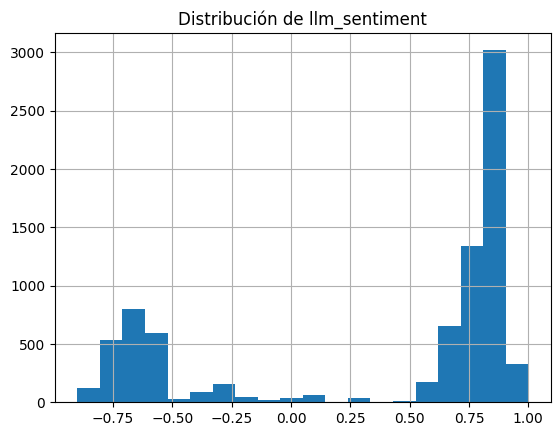

In [ ]:
# Visualizing the distribution of llm_sentiment
df_WS['llm_sentiment'].hist(bins=20)
plt.title('llm_sentiment distribution')
plt.show()

llm_sentiment shows the strongest correlation so far with the target variable RepeatPurchase.

In [16]:
df_WS.columns

Index(['Country', 'Sub-Category', 'Segment', 'Ship Mode', 'FeedbackText',
       'RepeatPurchase', 'Order Prefix', 'Month', 'Half-month', 'Weekday',
       'Discount', 'Profit', 'llm_sentiment'],
      dtype='object')

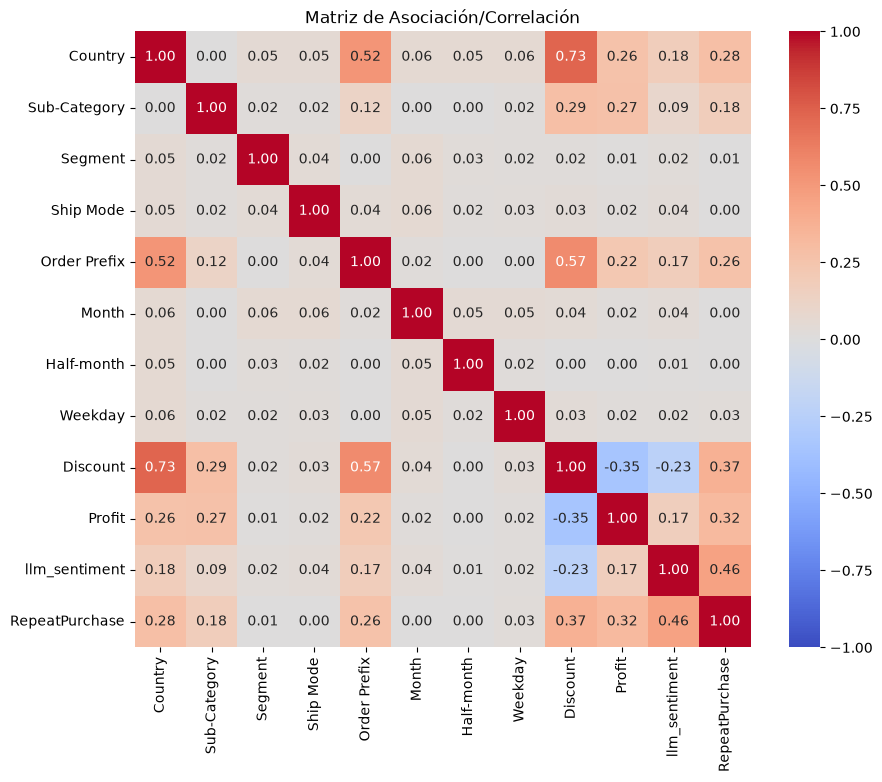

In [ ]:
# Visualizing the association/correlation matrix to determine which variables to use
#!pip install dython --quiet
from dython.nominal import associations
cols_to_check = ['Country', 'Sub-Category', 'Segment', 'Ship Mode', 'Order Prefix',
                  'Month', 'Half-month', 'Weekday', 'Discount', 'Profit', 'llm_sentiment', 'RepeatPurchase']

nominal_cols = ['Country', 'Sub-Category', 'Segment', 'Ship Mode', 'Order Prefix',
                 'Month', 'Half-month', 'Weekday', 'RepeatPurchase']

result = associations(df_WS[cols_to_check],
                       nominal_columns=nominal_cols,
                       figsize=(10, 8),
                       cmap='coolwarm',
                       title='Association/Correlation Matrix')

'Segment', 'Ship Mode', 'Month', 'Half-month', 'Weekday' show no association/correlation with any variable, therefore, we will drop. We will also drop 'FeedbackText' since we will use 'llm_sentiment'.

In [4]:
df_WS = df_WS.drop(columns=['Segment', 'Ship Mode', 'Month', 'Half-month', 'Weekday', 'FeedbackText'])
df_WS.columns

Index(['Country', 'Sub-Category', 'RepeatPurchase', 'Order Prefix', 'Discount',
       'Profit', 'llm_sentiment'],
      dtype='object')

# **MODELING: CatBoost**

Given that we have two high-cardinality categorical variables (Country and Sub-Category) and given that the association/correlation matrix showed that several variables have a moderate-to-strong association/correlation, we chose the CatBoost model, which is a good candidate for overcoming these two challenges.

In [5]:
# Train-test split
X = df_WS.drop(columns=['RepeatPurchase'])
y = df_WS['RepeatPurchase']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cat_features = ['Country', 'Sub-Category', 'Order Prefix']
train_pool = Pool(X_train, y_train, cat_features=cat_features)
test_pool = Pool(X_test, y_test, cat_features=cat_features)

In [ ]:
# Baseline model
model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    eval_metric='AUC',
    random_seed=42,
    verbose=100  # prints progress every 100 iterations
)

model.fit(train_pool, eval_set=test_pool, early_stopping_rounds=50)

0:	test: 0.8431935	best: 0.8431935 (0)	total: 9.41ms	remaining: 4.7s
100:	test: 0.8610043	best: 0.8614134 (81)	total: 787ms	remaining: 3.11s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8614134474
bestIteration = 81

Shrink model to first 82 iterations.


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, random_seed=42, verbose=100)

In [ ]:
# Evaluation Metrics for the Baseline Model
y_pred = model.predict(test_pool)
y_pred_proba = model.predict_proba(test_pool)[:, 1]

print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.68      0.75       711
           1       0.78      0.89      0.83       899

    accuracy                           0.80      1610
   macro avg       0.80      0.78      0.79      1610
weighted avg       0.80      0.80      0.79      1610

ROC-AUC: 0.8614
[[483 228]
 [100 799]]


In [14]:
# Feature importance
importances = model.get_feature_importance(train_pool)
feature_names = X_train.columns

imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
imp_df.sort_values('importance', ascending=False)

,feature,importance
4,Profit,40.250795
5,llm_sentiment,39.521014
1,Sub-Category,8.534307
3,Discount,6.599233
0,Country,3.633651
2,Order Prefix,1.461000


We established a baseline model with an accuracy of 0.80 and a ROC-AUC of 0.86. We consider these to be good metrics for understanding the RepeatPurchase phenomenon.<br>
On the other hand, the feature importance ranking places Profit as the most important feature. It can be assumed that this is due to its association/correlation with other variables such as Discount, Sub-Category, and Country; in other words, all of these variables are important, but the model found Profit to be more efficient for making splits.<br>
We will try optimizing the hyperparameters using random search.

In [ ]:
# Optimizing hyperparameters with random search
param_grid = {
    'depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'iterations': [500, 1000]
}

model = CatBoostClassifier(
    eval_metric='AUC',
    random_seed=42,
    verbose=0
)

randomized_search_result = model.randomized_search(
    param_grid,
    X=train_pool,
    cv=5,
    n_iter=30,  # number of random combinations to try
    partition_random_seed=42,
    verbose=False
)

print(randomized_search_result['params'])

In [ ]:
# Retraining with the best parameters and evaluating with the test set
best_model = CatBoostClassifier(
    **randomized_search_result['params'],
    eval_metric='AUC',
    random_seed=42,
    verbose=100
)
best_model.fit(train_pool, eval_set=test_pool, early_stopping_rounds=50)

y_pred_tuned = best_model.predict(test_pool)
y_pred_proba_tuned = best_model.predict_proba(test_pool)[:, 1]

print(classification_report(y_test, y_pred_tuned))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_tuned):.4f}")

0:	test: 0.8451812	best: 0.8451812 (0)	total: 13ms	remaining: 6.47s
100:	test: 0.8594727	best: 0.8599170 (85)	total: 1.08s	remaining: 4.26s
200:	test: 0.8598192	best: 0.8602276 (165)	total: 2.1s	remaining: 3.12s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8602275696
bestIteration = 165

Shrink model to first 166 iterations.
              precision    recall  f1-score   support

           0       0.83      0.68      0.75       711
           1       0.78      0.89      0.83       899

    accuracy                           0.80      1610
   macro avg       0.81      0.79      0.79      1610
weighted avg       0.80      0.80      0.79      1610

ROC-AUC: 0.8602


With the optimized hyperparameters there was no improvement in ROC-AUC (0.86).

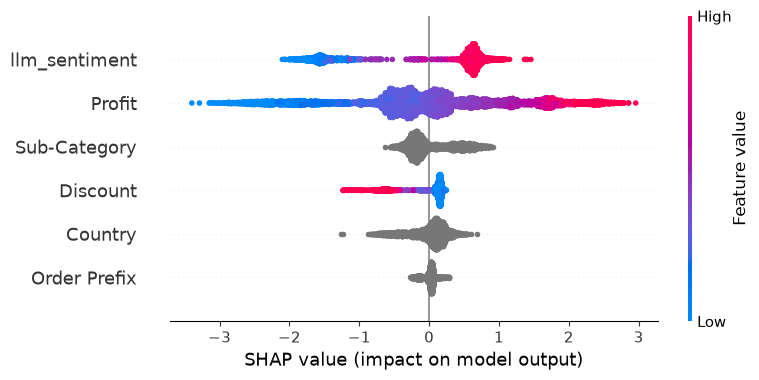

In [ ]:
# !pip install shap --quiet
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(train_pool)

shap.summary_plot(shap_values, X_train, feature_names=X_train.columns)

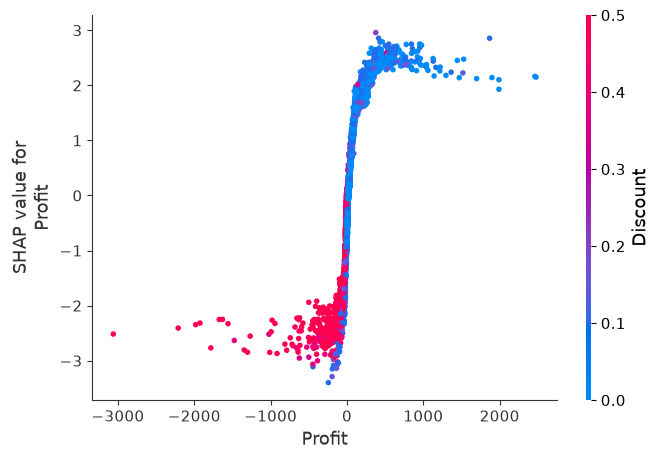

In [9]:
shap.dependence_plot('Profit', shap_values, X_train, interaction_index='Discount')